<a href="https://colab.research.google.com/github/Aigulya0/titanic-eda-1/blob/main/Practical_3_Penguins_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем датасет напрямую из интернета
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"

df = pd.read_csv(url)

print("Датасет успешно загружен!")
print("Размер датасета:", df.shape)

display(df.head())


Датасет успешно загружен!
Размер датасета: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(
    "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
)

print("Датасет успешно загружен!")
display(df.head())


Датасет успешно загружен!


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:

print("Типы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nСтатистика:")
display(df.describe(include="all"))



Типы данных:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
dtype: object

Пропущенные значения:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Статистика:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,333
unique,3,3,NaN,NaN,NaN,NaN,2
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,MALE
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


In [ ]:

numeric_features = ["age", "sibsp", "parch", "fare"]
categorical_features = [
    "pclass", "sex", "embarked", "class",
    "who", "adult_male", "deck",
    "embark_town", "alive", "alone"
]
target = "survived"

print("Числовые:", numeric_features)
print("Категориальные:", categorical_features)
print("Целевая переменная:", target)


Числовые: ['age', 'sibsp', 'parch', 'fare']
Категориальные: ['pclass', 'sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']
Целевая переменная: survived


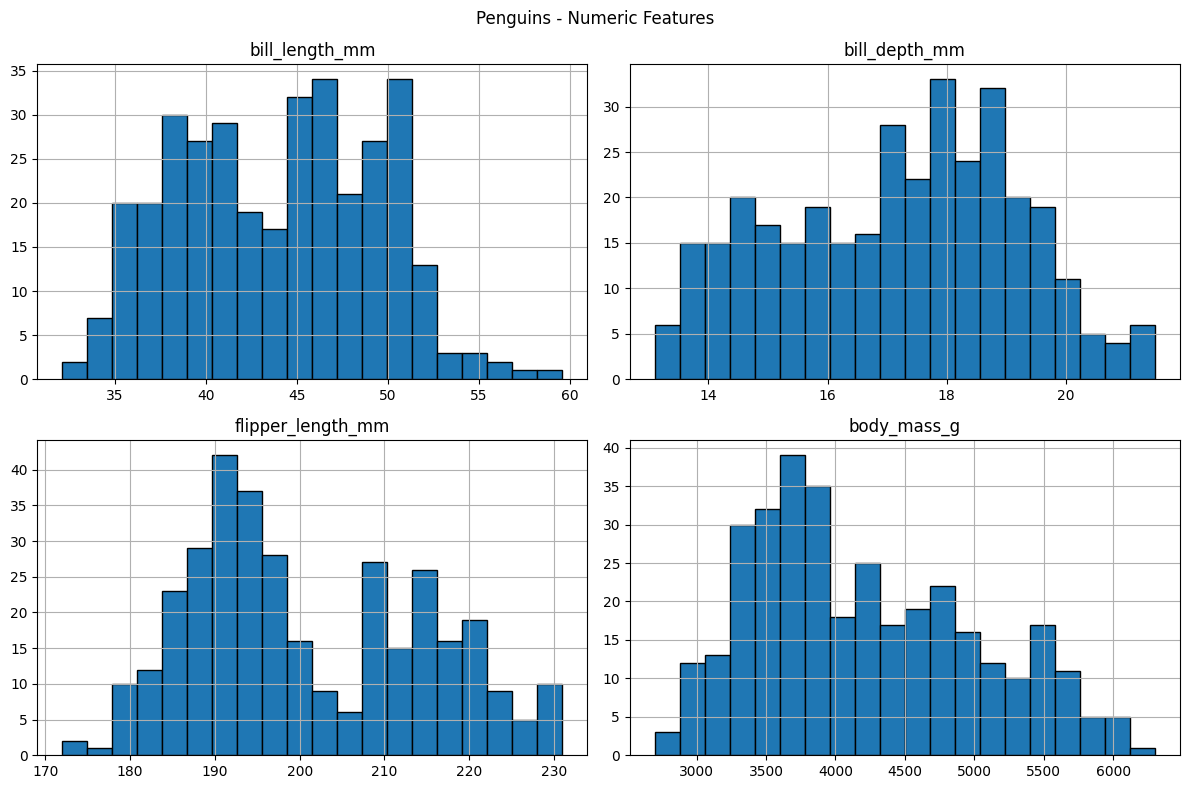

In [ ]:

# Числовые признаки датасета Penguins
numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Строим графики распределения
df[numeric_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Penguins - Numeric Features")
plt.tight_layout()
plt.show()


In [ ]:

numeric_features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

categorical_features = [
    "species",
    "island",
    "sex"
]

target = "species"

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)
print("Целевая переменная:", target)


Числовые признаки: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Категориальные признаки: ['species', 'island', 'sex']
Целевая переменная: species


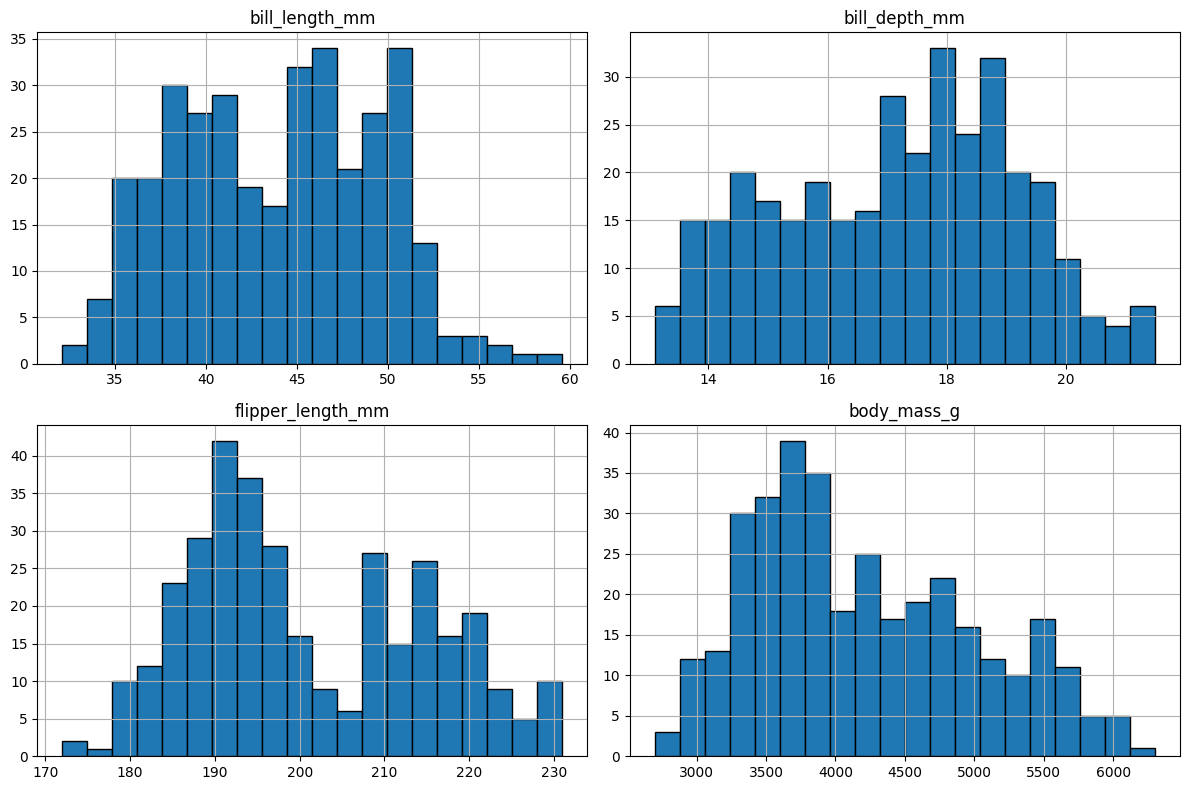

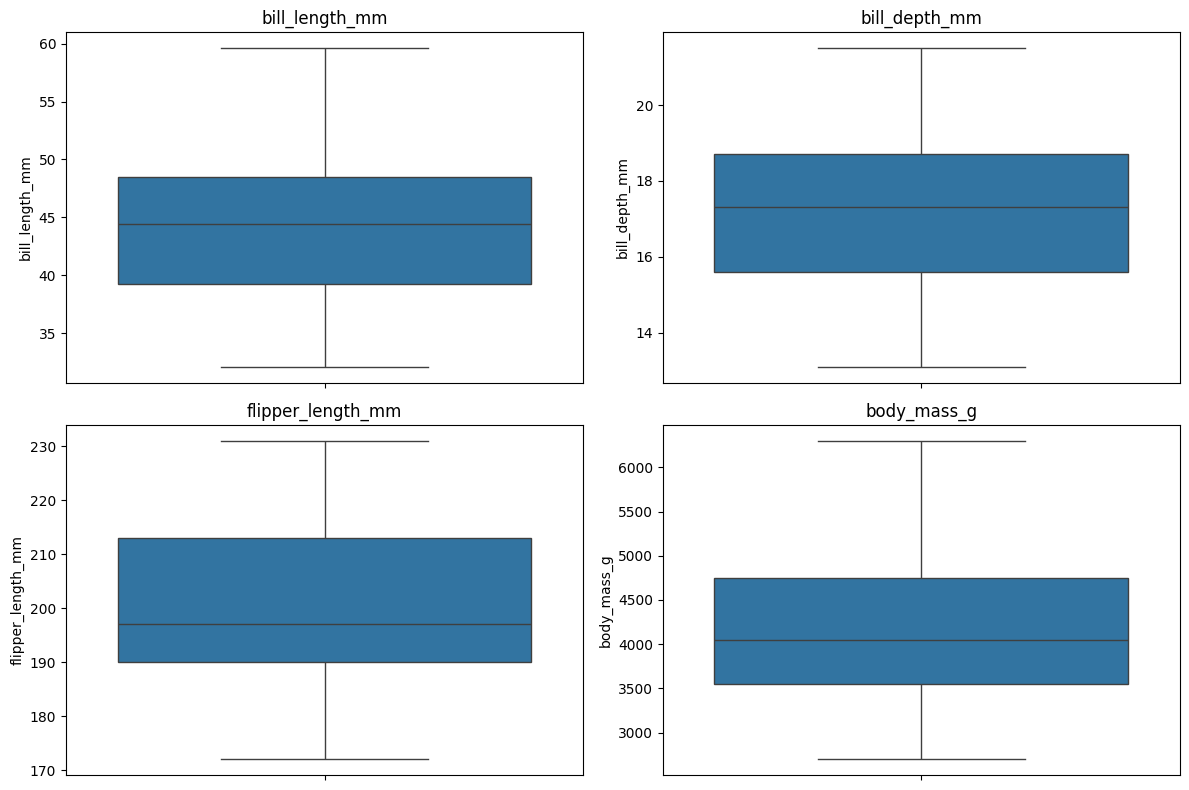

In [ ]:

df[numeric_features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, col in zip(axes.flat, numeric_features):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


In [ ]:

for col in numeric_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) |
             (df[col] > upper)).sum()

    print(col, "Выбросов:", count)


bill_length_mm Выбросов: 0
bill_depth_mm Выбросов: 0
flipper_length_mm Выбросов: 0
body_mass_g Выбросов: 0



 species
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
Редкие категории (<5%):
Series([], Name: proportion, dtype: float64)

 island
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64
Редкие категории (<5%):
Series([], Name: proportion, dtype: float64)

 sex
sex
MALE      168
FEMALE    165
NaN        11
Name: count, dtype: int64
Редкие категории (<5%):
Series([], Name: proportion, dtype: float64)


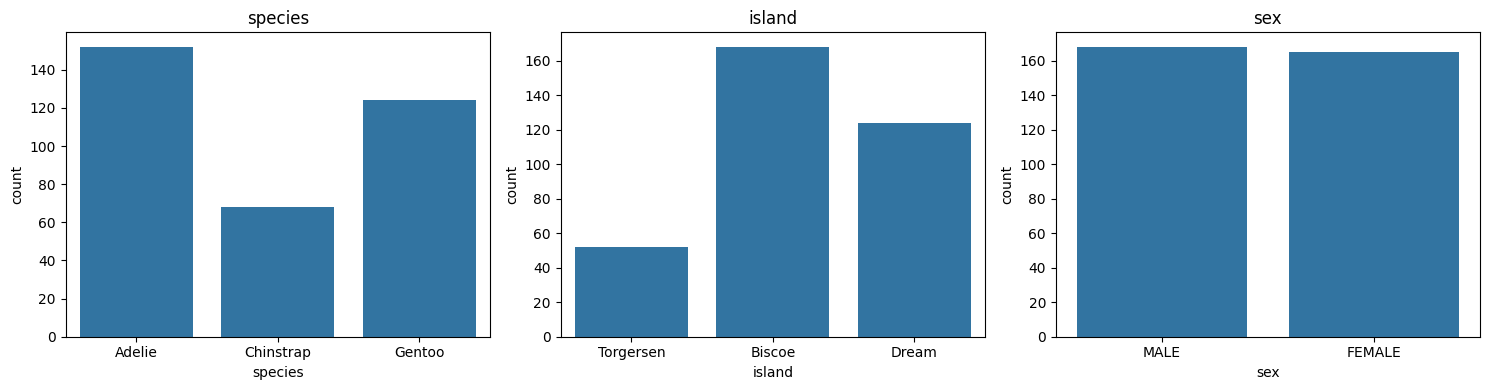

In [ ]:

for col in categorical_features:
    print("\n", col)
    print(df[col].value_counts(dropna=False))

    rare = df[col].value_counts(normalize=True)
    print("Редкие категории (<5%):")
    print(rare[rare < 0.05])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, categorical_features):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()



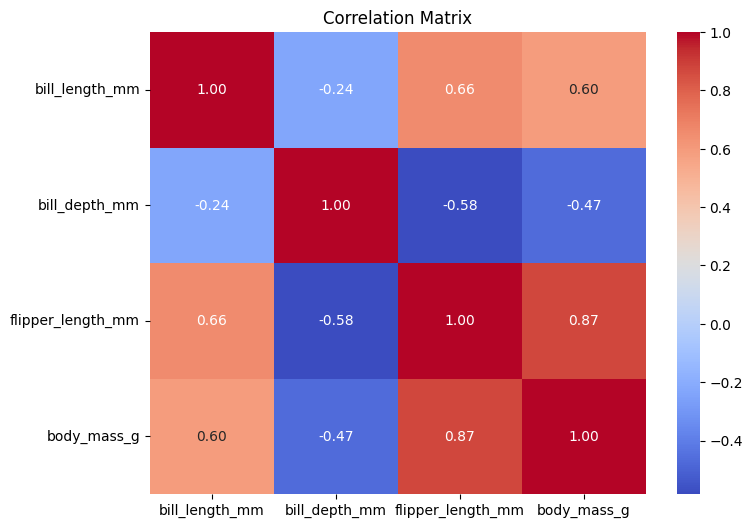

In [ ]:

corr = df[numeric_features].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Matrix")
plt.show()


Выбранные признаки: ['flipper_length_mm', 'body_mass_g', 'bill_length_mm']


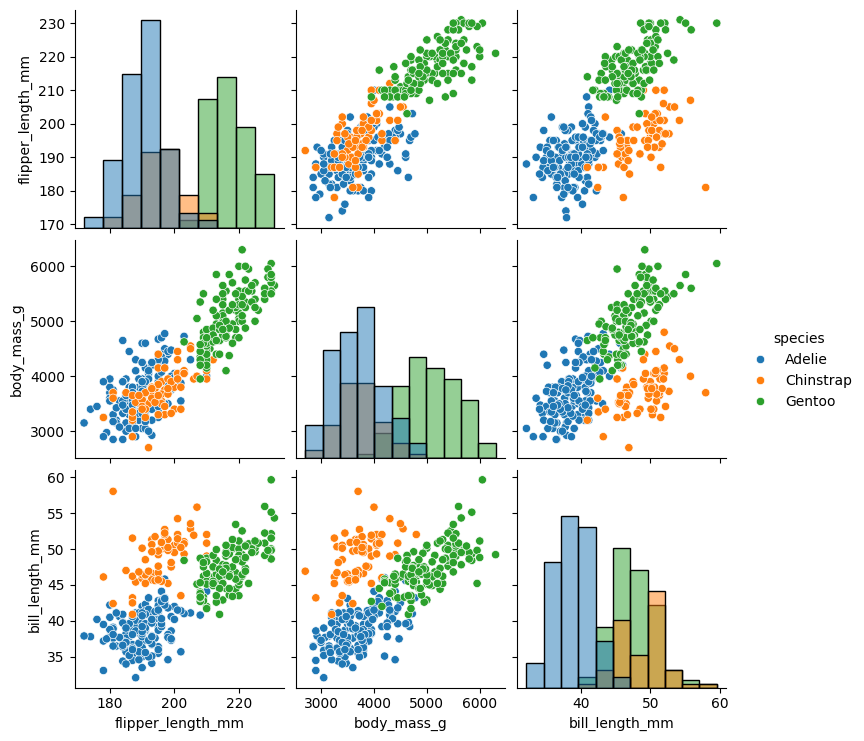

In [ ]:

from itertools import combinations

pairs = sorted(
    combinations(numeric_features, 2),
    key=lambda p: abs(corr.loc[p[0], p[1]]),
    reverse=True
)

selected = list(dict.fromkeys(
    [x for pair in pairs[:3] for x in pair]
))

print("Выбранные признаки:", selected)

sns.pairplot(
    df,
    vars=selected,
    hue="species",
    diag_kind="hist"
)
plt.show()


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Проценты:
species
Adelie       44.186047
Gentoo       36.046512
Chinstrap    19.767442
Name: proportion, dtype: float64


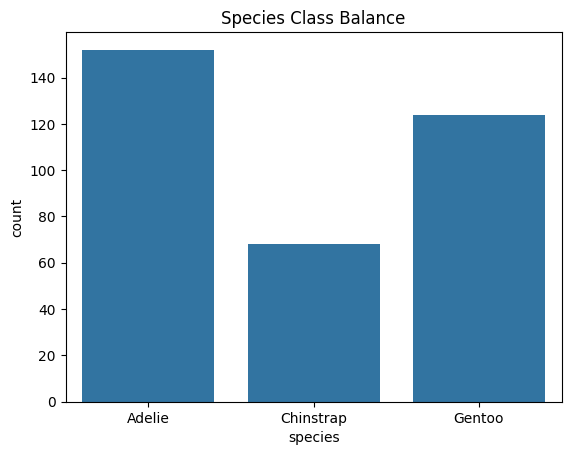

In [ ]:

print(df["species"].value_counts())

print("\nПроценты:")
print(
    df["species"].value_counts(normalize=True) * 100
)

sns.countplot(data=df, x="species")
plt.title("Species Class Balance")
plt.show()


# Практическая работа №3
## Разведочный анализ данных (EDA)

**Студент:** Айгуль Абдуллаева  
**Вариант:** B  
**Датасет:** Palmer Penguins (Пингвины)  
**Среда разработки:** Google Colab  
**Язык программирования:** Python

### 1. Цель работы

Провести полный разведочный анализ данных (EDA), изучить структуру датасета, выявить пропущенные значения, выбросы и взаимосвязи между признаками.

### 2. Описание датасета

Для выполнения практической работы использован датасет Palmer Penguins, содержащий информацию о 344 пингвинах и 7 признаках.

**Ссылка на датасет:**  
https://github.com/mwaskom/seaborn-data/blob/master/penguins.csv

Основные признаки:
- `species` — вид пингвина.
- `island` — остров обитания.
- `bill_length_mm` — длина клюва.
- `bill_depth_mm` — глубина клюва.
- `flipper_length_mm` — длина ласт.
- `body_mass_g` — масса тела.
- `sex` — пол пингвина.

Целевая переменная — `species`.

### 3. Используемые инструменты

- Google Colab — среда выполнения кода.
- Python — язык программирования.
- Pandas — обработка и анализ данных.
- NumPy — числовые вычисления.
- Matplotlib — построение графиков.
- Seaborn — визуализация данных.

### 4. Выполненные задания

1. Загружен датасет и проведён общий осмотр данных.
2. Определены числовые и категориальные признаки.
3. Проверены пропущенные значения.
4. Построены гистограммы распределения числовых признаков.
5. Проверено наличие выбросов с помощью boxplot и метода IQR.
6. Изучены частоты категориальных признаков и редкие категории.
7. Построены корреляционная матрица и матрица диаграмм рассеяния.
8. Проверен баланс целевой переменной.

### 5. Результаты анализа

В результате анализа установлено:

- Датасет содержит 344 строки и 7 столбцов.
- В некоторых столбцах присутствуют пропущенные значения.
- Числовые признаки имеют различные распределения.
- Выполнена проверка потенциальных выбросов.
- Исследованы связи между числовыми признаками.
- Целевая переменная содержит три класса: Adelie, Gentoo и Chinstrap.
- Количество объектов в классах различается.

### 6. План дальнейшей работы

На следующем занятии планируется:

1. Обработать пропущенные значения.
2. Проверить потенциальные выбросы.
3. Закодировать категориальные признаки.
4. При необходимости масштабировать числовые данные.
5. Подготовить датасет к обучению модели машинного обучения.

### 7. Заключение

В ходе практической работы был проведён разведочный анализ данных Palmer Penguins с использованием Python и Google Colab.

Были изучены характеристики датасета, построены графики и выявлены особенности данных, которые необходимо учитывать при дальнейшей обработке.

**Цель практической работы достигнута.**